# Taller — Aprendizaje profundo: reconocimiento de dígitos manuscritos
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**

*Cuaderno RESUELTO paso a paso, para trabajo asíncrono.* Léalo en orden, ejecute cada celda y compare con los **puntos de control**. Después resuelva el cuaderno del taller propuesto, que usa otro conjunto de datos.

| | |
|---|---|
| **Entorno** | Google Colab (Entorno de ejecución → Cambiar tipo → GPU T4 si está disponible; funciona también en CPU) |
| **Marco** | PyTorch + torchvision |
| **Conjunto de datos** | MNIST: 70 000 imágenes de dígitos manuscritos en escala de grises, 28×28 px, 10 clases (60 000 entrenamiento, 10 000 prueba) |

### Objetivos de aprendizaje
1. **Explicar** cómo una red convolucional extrae rasgos de una imagen (convolución, no linealidad, *pooling*).
2. **Implementar** un perceptrón multicapa y una CNN en PyTorch y **entrenarlas** con retropropagación y Adam.
3. **Evaluar** con particiones entrenamiento/validación/prueba, curvas y matriz de confusión.
4. **Diagnosticar** sobreajuste y **justificar** decisiones de diseño con evidencia.

### Cómo se evalúa este taller
Evaluación al final (formativa) → test de 10 preguntas en Classroom (calificado) → cuaderno propuesto con informe corto.

> **Nota sobre los valores esperados.** Los rangos de exactitud que aparecen abajo son orientativos y corresponden a lo que suele obtenerse con MNIST. El autor de este material los escribió sin poder descargar MNIST al probar el código; verifique los suyos y no los trate como una garantía.

## Paso 0. Preparar el entorno
Importamos las librerías, fijamos la semilla (para que los resultados se repitan) y escogemos CPU o GPU. Se define también `verificar`, que imprime `[OK]` o `[REVISAR]` en los puntos de control.

In [1]:
# ---- Preparación del entorno (Colab ya trae PyTorch, torchvision y scikit-learn) ----
import random, time, hashlib, os, shutil
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix

SEMILLA = 42                      # misma semilla = mismos resultados (reproducibilidad)
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
fijar_semilla()

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", dispositivo)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok


PyTorch 2.11.0+cu130 | dispositivo: cuda


## Paso 1. Los datos
Cada imagen es una matriz de 28×28 con valores de 0 (fondo) a 255 (trazo). Las convertimos a números reales en [0, 1] y a tensores con forma **N × 1 × 28 × 28** (N imágenes, 1 canal, alto, ancho).

La celda siguiente define funciones auxiliares; ejecútela sin modificarla.

In [2]:
# ---- Funciones de datos (no necesita modificarlas) ----
def cargar_dataset(nombre="MNIST", raiz="datos"):
    """Descarga el conjunto con torchvision y devuelve tensores en [0,1] con forma N x 1 x 28 x 28.
    Si no hay internet, usa un conjunto de RESPALDO (digits de scikit-learn) y avisa."""
    from torchvision import datasets
    try:
        clase = getattr(datasets, nombre)
        tr = clase(raiz, train=True, download=True)
        te = clase(raiz, train=False, download=True)
        Xtr = tr.data.float().div(255).unsqueeze(1)
        Xte = te.data.float().div(255).unsqueeze(1)
        return Xtr, tr.targets.clone(), Xte, te.targets.clone(), list(tr.classes), False
    except Exception as e:
        print("AVISO: no se pudo descargar", nombre, "->", type(e).__name__)
        print("Se usa un conjunto de RESPALDO (sklearn digits: 1797 imágenes 8x8 escaladas a 28x28).")
        print("Sirve para probar el código, pero NO es", nombre, "y las exactitudes serán distintas.")
        from sklearn.datasets import load_digits
        d = load_digits()
        X = torch.tensor(d.images, dtype=torch.float32).div(16).unsqueeze(1)
        X = F.interpolate(X, size=28, mode="bilinear", align_corners=False)
        y = torch.tensor(d.target, dtype=torch.long)
        g = torch.Generator().manual_seed(SEMILLA)
        p = torch.randperm(len(y), generator=g)
        n_te = len(y) // 5
        return X[p[n_te:]], y[p[n_te:]], X[p[:n_te]], y[p[:n_te]], [str(i) for i in range(10)], True


def preparar_datos(nombre="MNIST", n_val=5000, batch=64):
    """Carga, separa entrenamiento/validación/prueba y normaliza SOLO con estadísticos de entrenamiento."""
    Xtr, ytr, Xte, yte, clases, respaldo = cargar_dataset(nombre)
    n_val = min(n_val, len(ytr) // 10)
    g = torch.Generator().manual_seed(SEMILLA)
    p = torch.randperm(len(ytr), generator=g)
    iv, it = p[:n_val], p[n_val:]
    Xt, yt, Xv, yv = Xtr[it], ytr[it], Xtr[iv], ytr[iv]
    media, desv = Xt.mean().item(), Xt.std().item()
    norm = lambda X: (X - media) / desv
    d = dict(nombre=nombre, clases=clases, respaldo=respaldo, media=media, desv=desv,
             Xraw_tr=Xt, Xraw_te=Xte,
             X_tr=norm(Xt), y_tr=yt, X_val=norm(Xv), y_val=yv, X_te=norm(Xte), y_te=yte)
    d["dl_tr"] = DataLoader(TensorDataset(d["X_tr"], yt), batch_size=batch, shuffle=True, generator=g)
    d["dl_val"] = DataLoader(TensorDataset(d["X_val"], yv), batch_size=512)
    d["dl_te"] = DataLoader(TensorDataset(d["X_te"], d["y_te"]), batch_size=512)
    return d


def mostrar_muestras(X, y, clases, n=16, titulo=""):
    fig, ejes = plt.subplots(2, n // 2, figsize=(1.4 * n // 2, 3.2))
    for ax, i in zip(ejes.ravel(), range(n)):
        ax.imshow(X[i, 0], cmap="gray"); ax.set_title(clases[int(y[i])], fontsize=9); ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.60MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.97MB/s]


Entrenamiento: (55000, 1, 28, 28) | Validación: (5000, 1, 28, 28) | Prueba: (10000, 1, 28, 28)
Media y desviación usadas (solo entrenamiento): 0.1307  0.3081


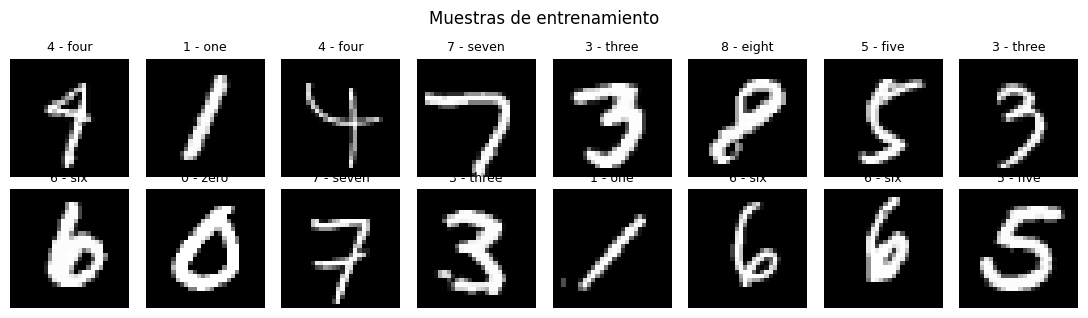

In [3]:
datos = preparar_datos("MNIST")
clases = datos["clases"]
print("Entrenamiento:", tuple(datos["X_tr"].shape), "| Validación:", tuple(datos["X_val"].shape), "| Prueba:", tuple(datos["X_te"].shape))
print("Media y desviación usadas (solo entrenamiento): %.4f  %.4f" % (datos["media"], datos["desv"]))
mostrar_muestras(datos["Xraw_tr"], datos["y_tr"], clases, 16, "Muestras de entrenamiento")

In [4]:
# PUNTO DE CONTROL 1
verificar("Forma de las imágenes N x 1 x 28 x 28", tuple(datos["X_tr"].shape[1:]) == (1, 28, 28), "revise la carga de datos")
verificar("10 clases", len(clases) == 10, "MNIST tiene 10 dígitos")
verificar("Normalizado: media ~ 0 y desviación ~ 1", abs(datos["X_tr"].mean().item()) < 0.05 and abs(datos["X_tr"].std().item() - 1) < 0.05, "")
conteo = torch.bincount(datos["y_tr"], minlength=10)
print("Imágenes por clase (entrenamiento):", conteo.tolist())

[OK]      Forma de las imágenes N x 1 x 28 x 28
[OK]      10 clases
[OK]      Normalizado: media ~ 0 y desviación ~ 1
Imágenes por clase (entrenamiento): [5424, 6188, 5441, 5610, 5378, 4946, 5449, 5755, 5320, 5489]


**Qué observar.** Las clases están casi balanceadas. Si una clase tuviera muy pocas imágenes, la exactitud global podría ocultar un mal desempeño en ella; por eso más adelante miramos la matriz de confusión.

**Normalización.** Restamos la media y dividimos por la desviación estándar, calculadas **solo con el conjunto de entrenamiento**. Si usáramos también validación o prueba, estaríamos filtrando información del futuro hacia el entrenamiento.

## Paso 2. Línea base: perceptrón multicapa (MLP)
Antes de usar convoluciones conviene tener una referencia. El MLP aplana la imagen (784 valores) y la pasa por una capa oculta de 128 neuronas con ReLU:

$$\mathbf{h}=\mathrm{ReLU}(W_1\mathbf{x}+\mathbf{b}_1),\qquad \mathbf{z}=W_2\mathbf{h}+\mathbf{b}_2$$

La salida $\mathbf{z}$ son 10 *logits*. La probabilidad de cada clase es $p_k=\dfrac{e^{z_k}}{\sum_j e^{z_j}}$ (softmax) y la pérdida es la **entropía cruzada** $L=-\ln p_{y}$, donde $y$ es la clase correcta. Esto es lo mismo que vio en el Taller 2 (retropropagación), con otra función de activación y otra pérdida.

**Pregunta guía:** ¿cuántos parámetros tiene este modelo? Calcúlelo a mano y compárelo con el resultado.

In [5]:
@torch.no_grad()
def evaluar(modelo, dl):
    """Devuelve pérdida media, exactitud, etiquetas reales y predichas."""
    modelo.eval(); ls, ok, n = 0.0, 0, 0
    reales, preds = [], []
    for xb, yb in dl:
        xb, yb = xb.to(dispositivo), yb.to(dispositivo)
        salida = modelo(xb)
        ls += F.cross_entropy(salida, yb, reduction="sum").item()
        pred = salida.argmax(1)
        ok += (pred == yb).sum().item(); n += len(yb)
        reales.append(yb.cpu()); preds.append(pred.cpu())
    return ls / n, ok / n, torch.cat(reales).numpy(), torch.cat(preds).numpy()


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def graficar_curvas(hist, titulo=""):
    ep = range(1, len(hist["loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(ep, hist["loss"], "o-", label="entrenamiento"); a1.plot(ep, hist["val_loss"], "s-", label="validación")
    a1.set_xlabel("época"); a1.set_ylabel("pérdida (entropía cruzada)"); a1.legend(); a1.grid(alpha=.3)
    a2.plot(ep, hist["acc"], "o-", label="entrenamiento"); a2.plot(ep, hist["val_acc"], "s-", label="validación")
    a2.set_xlabel("época"); a2.set_ylabel("exactitud"); a2.legend(); a2.grid(alpha=.3)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


def graficar_confusion(cm, clases, titulo="Matriz de confusión"):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues"); fig.colorbar(im, fraction=0.046)
    ax.set_xticks(range(len(clases))); ax.set_yticks(range(len(clases)))
    ax.set_xticklabels(clases, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(clases, fontsize=8)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(titulo)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.show()


In [6]:
def entrenar(modelo, dl_tr, dl_val, epocas=3, lr=1e-3, aumentar=None):
    """Bucle de entrenamiento con Adam y entropía cruzada. Devuelve el historial por época."""
    modelo.to(dispositivo)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
    for ep in range(epocas):
        modelo.train(); ls, ok, n = 0.0, 0, 0
        t0 = time.time()
        for xb, yb in dl_tr:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            if aumentar is not None:
                xb = aumentar(xb)
            opt.zero_grad()                              # 1) borrar gradientes de la iteración anterior
            salida = modelo(xb)                          # 2) propagación hacia adelante (logits)
            perdida = F.cross_entropy(salida, yb)        # 3) pérdida: softmax + entropía cruzada
            perdida.backward()                           # 4) retropropagación: calcula dL/dW
            opt.step()                                   # 5) Adam actualiza los pesos
            ls += perdida.item() * len(yb); ok += (salida.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va, _, _ = evaluar(modelo, dl_val)
        hist["loss"].append(ls / n); hist["acc"].append(ok / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"época {ep+1}/{epocas}  pérdida {ls/n:.4f}  exact {ok/n:.4f}  |  val_pérdida {vl:.4f}  val_exact {va:.4f}  ({time.time()-t0:.0f}s)")
    return hist


Parámetros del MLP: 101770
época 1/3  pérdida 0.2652  exact 0.9227  |  val_pérdida 0.1618  val_exact 0.9500  (3s)
época 2/3  pérdida 0.1177  exact 0.9646  |  val_pérdida 0.1142  val_exact 0.9642  (2s)
época 3/3  pérdida 0.0823  exact 0.9749  |  val_pérdida 0.1084  val_exact 0.9686  (2s)


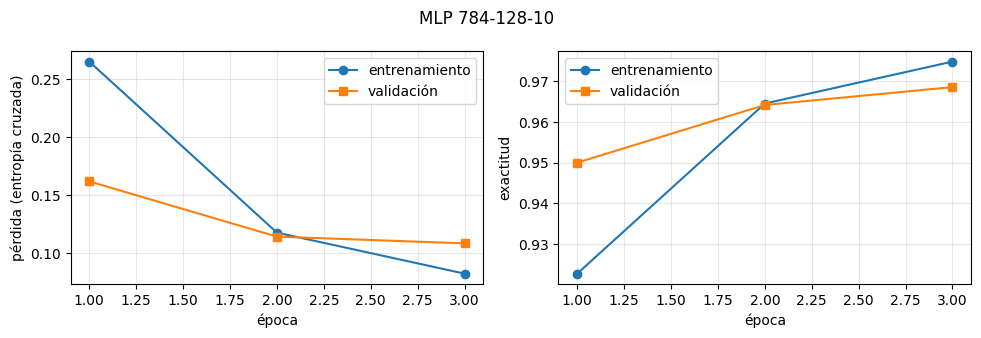

In [7]:
EPOCAS = 3
fijar_semilla()
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
print("Parámetros del MLP:", contar_parametros(mlp))
hist_mlp = entrenar(mlp, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3)
graficar_curvas(hist_mlp, "MLP 784-128-10")

In [8]:
# PUNTO DE CONTROL 2
verificar("Parámetros del MLP = 784*128+128 + 128*10+10 = 101 770", contar_parametros(mlp) == 101770, "recalcule: pesos + sesgos de cada capa")
verificar("La pérdida de entrenamiento baja de época en época", all(b < a for a, b in zip(hist_mlp["loss"], hist_mlp["loss"][1:])), "pruebe otra semilla o menos épocas")
umbral = 0.80 if datos["respaldo"] else 0.95     # con MNIST real se espera bastante más; el respaldo es solo para probar
verificar(f"Exactitud de validación > {umbral:.0%}", hist_mlp["val_acc"][-1] > umbral, "revise la normalización y el paso de entrenamiento")
print("Valor típico con MNIST real tras 3 épocas: 96 % a 98 % (orientativo).")

[OK]      Parámetros del MLP = 784*128+128 + 128*10+10 = 101 770
[OK]      La pérdida de entrenamiento baja de época en época
[OK]      Exactitud de validación > 95%
Valor típico con MNIST real tras 3 épocas: 96 % a 98 % (orientativo).


## Paso 3. Red convolucional (CNN)
El MLP ignora que los píxeles vecinos están relacionados. Una **convolución** desliza un filtro pequeño (aquí 3×3) por toda la imagen y calcula en cada posición una suma ponderada; los **mismos pesos** se reutilizan en todas las posiciones, lo que reduce parámetros y da cierta invarianza a traslaciones. Una capa `Conv2d(c_in, c_out, k)` tiene $c_{out}(c_{in}k^2+1)$ parámetros.

Tamaño espacial sin relleno: $\text{salida}=\text{entrada}-k+1$. El *max-pooling* 2×2 divide el tamaño entre 2.

| Capa | Salida | Parámetros |
|---|---|---|
| Entrada | 1×28×28 | 0 |
| Conv 3×3, 16 filtros + ReLU | 16×26×26 | 160 |
| MaxPool 2×2 | 16×13×13 | 0 |
| Conv 3×3, 32 filtros + ReLU | 32×11×11 | 4 640 |
| MaxPool 2×2 | 32×5×5 | 0 |
| Aplanar + Dropout (0.25) | 800 | 0 |
| Lineal 800→10 | 10 | 8 010 |

Total: 12 810 parámetros, unas ocho veces menos que el MLP.

Parámetros de la CNN: 12810
Forma de salida para un lote de 4 imágenes: (4, 10)
época 1/3  pérdida 0.2306  exact 0.9301  |  val_pérdida 0.0863  val_exact 0.9748  (3s)
época 2/3  pérdida 0.0814  exact 0.9752  |  val_pérdida 0.0646  val_exact 0.9804  (2s)
época 3/3  pérdida 0.0620  exact 0.9808  |  val_pérdida 0.0484  val_exact 0.9858  (2s)


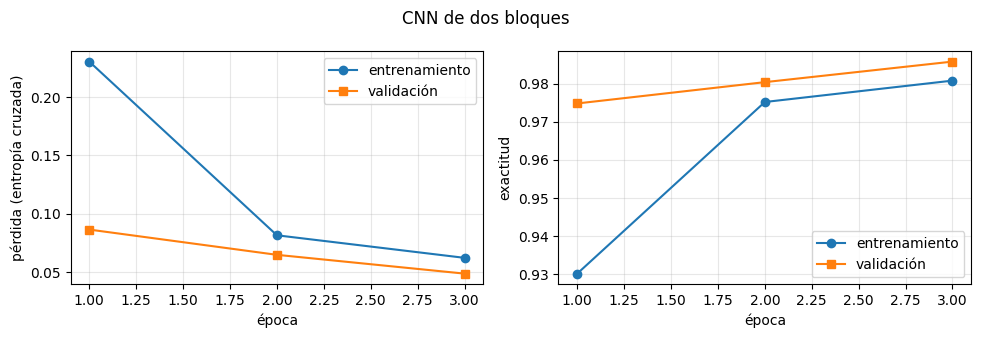

In [9]:
class CNN(nn.Module):
    def __init__(self, p_drop=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3)     # 28 -> 26
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3)    # 13 -> 11
        self.drop = nn.Dropout(p_drop)                   # apaga neuronas al azar SOLO en entrenamiento
        self.fc = nn.Linear(32 * 5 * 5, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)       # 26 -> 13
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)       # 11 -> 5
        x = self.drop(x.flatten(1))
        return self.fc(x)                                # logits (la softmax va dentro de la pérdida)

fijar_semilla()
cnn = CNN()
print("Parámetros de la CNN:", contar_parametros(cnn))
print("Forma de salida para un lote de 4 imágenes:", tuple(cnn.to(dispositivo)(datos["X_tr"][:4].to(dispositivo)).shape))
hist_cnn = entrenar(cnn, datos["dl_tr"], datos["dl_val"], epocas=EPOCAS, lr=1e-3)
graficar_curvas(hist_cnn, "CNN de dos bloques")

In [10]:
# PUNTO DE CONTROL 3
verificar("Parámetros de la CNN = 160 + 4 640 + 8 010 = 12 810", contar_parametros(cnn) == 12810, "compare con la tabla")
umbral = 0.80 if datos["respaldo"] else 0.97
verificar(f"Exactitud de validación > {umbral:.0%}", hist_cnn["val_acc"][-1] > umbral, "revise el entrenamiento")
print("Valor típico con MNIST real tras 3 épocas: 98.5 % a 99.2 % (orientativo).")
print("MLP: val_exact = %.4f   CNN: val_exact = %.4f" % (hist_mlp["val_acc"][-1], hist_cnn["val_acc"][-1]))

[OK]      Parámetros de la CNN = 160 + 4 640 + 8 010 = 12 810
[OK]      Exactitud de validación > 97%
Valor típico con MNIST real tras 3 épocas: 98.5 % a 99.2 % (orientativo).
MLP: val_exact = 0.9686   CNN: val_exact = 0.9858


**Qué observar.** Con MNIST real la CNN suele superar al MLP aun con muchos menos parámetros. Si en su ejecución no ocurre (por ejemplo, con el conjunto de respaldo), no lo oculte: anótelo y explique posibles causas en el informe (pocas épocas, semilla, tamaño del conjunto).

## Paso 4. Evaluación final en el conjunto de prueba
El conjunto de prueba se usa **una sola vez**, al final, para estimar el desempeño real. Si ajustáramos decisiones mirándolo, dejaría de ser una estimación honesta.

Exactitud en prueba: 0.9867   pérdida: 0.0381   (133 errores de 10000)


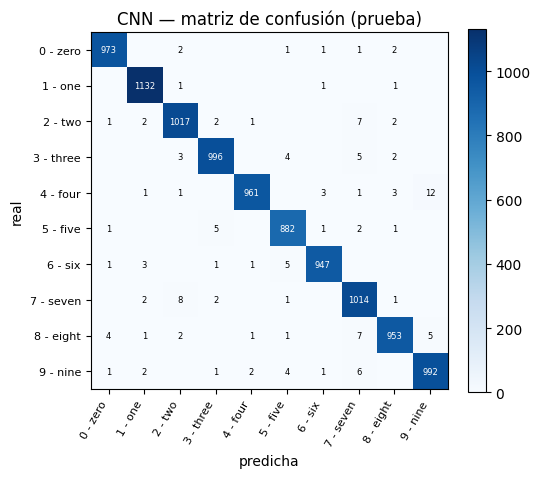

Real 4 - four -> predicha 9 - nine: 12 veces
Real 7 - seven -> predicha 2 - two: 8 veces
Real 2 - two -> predicha 7 - seven: 7 veces


In [11]:
perd_te, acc_te, y_real, y_pred = evaluar(cnn, datos["dl_te"])
print(f"Exactitud en prueba: {acc_te:.4f}   pérdida: {perd_te:.4f}   ({int(round((1-acc_te)*len(y_real)))} errores de {len(y_real)})")
cm = confusion_matrix(y_real, y_pred)
graficar_confusion(cm, clases, "CNN — matriz de confusión (prueba)")

# Pares de clases más confundidos
fuera = cm.copy(); np.fill_diagonal(fuera, 0)
for _ in range(3):
    i, j = np.unravel_index(np.argmax(fuera), fuera.shape)
    print(f"Real {clases[i]} -> predicha {clases[j]}: {fuera[i, j]} veces")
    fuera[i, j] = 0

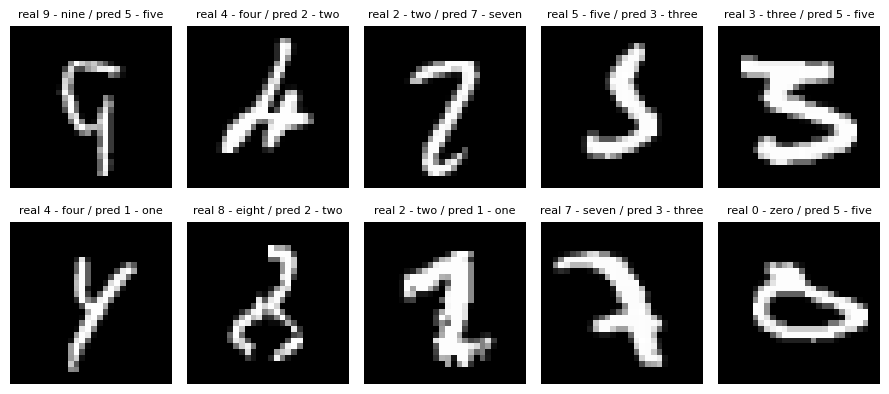

[OK]      La suma de la matriz de confusión = tamaño del conjunto de prueba


np.True_

In [12]:
# Algunos errores concretos
errores = np.where(y_real != y_pred)[0][:10]
if len(errores):
    fig, ejes = plt.subplots(2, 5, figsize=(9, 4.2))
    for ax, k in zip(ejes.ravel(), errores):
        ax.imshow(datos["Xraw_te"][k, 0], cmap="gray"); ax.axis("off")
        ax.set_title(f"real {clases[y_real[k]]} / pred {clases[y_pred[k]]}", fontsize=8)
    plt.tight_layout(); plt.show()
verificar("La suma de la matriz de confusión = tamaño del conjunto de prueba", cm.sum() == len(y_real), "")

## Paso 5. Mini-experimento: tasa de aprendizaje
Compare tres tasas de aprendizaje con 2 épocas cada una. **Antes de ejecutar, escriba su predicción:** ¿cuál será la mejor y por qué? Después compare.

In [13]:
resultados = []
for lr in [1e-1, 1e-3, 1e-5]:
    fijar_semilla()
    m = CNN()
    print(f"--- lr = {lr:g}")
    h_ = entrenar(m, datos["dl_tr"], datos["dl_val"], epocas=2, lr=lr)
    resultados.append((lr, h_["val_acc"][-1], h_["val_loss"][-1]))
print("\n lr        val_exact   val_pérdida")
for lr, a, l in resultados:
    print(f" {lr:<9g} {a:.4f}      {l:.4f}")

--- lr = 0.1
época 1/2  pérdida 2.4101  exact 0.1032  |  val_pérdida 2.3062  val_exact 0.1108  (2s)
época 2/2  pérdida 2.3092  exact 0.1052  |  val_pérdida 2.3045  val_exact 0.1042  (3s)
--- lr = 0.001
época 1/2  pérdida 0.2276  exact 0.9337  |  val_pérdida 0.0812  val_exact 0.9734  (7s)
época 2/2  pérdida 0.0805  exact 0.9754  |  val_pérdida 0.0584  val_exact 0.9800  (3s)
--- lr = 1e-05
época 1/2  pérdida 2.1596  exact 0.3050  |  val_pérdida 1.9070  val_exact 0.7126  (2s)
época 2/2  pérdida 1.5521  exact 0.6959  |  val_pérdida 1.1830  val_exact 0.8122  (2s)

 lr        val_exact   val_pérdida
 0.1       0.1042      2.3045
 0.001     0.9800      0.0584
 1e-05     0.8122      1.1830


**Interpretación esperada.** Una tasa muy alta puede hacer oscilar la pérdida o diverger; una muy baja avanza tan despacio que 2 épocas no bastan. Con Adam, valores cercanos a $10^{-3}$ suelen funcionar bien. Verifique si su resultado concuerda y anótelo.

## Paso 6. Guardar el modelo
Guardar los pesos permite reutilizar la red sin entrenarla de nuevo.

In [14]:
torch.save(cnn.state_dict(), "cnn_digitos.pt")
nuevo = CNN().to(dispositivo); nuevo.load_state_dict(torch.load("cnn_digitos.pt", map_location=dispositivo))
_, acc_recargado, _, _ = evaluar(nuevo, datos["dl_te"])
verificar("El modelo recargado da la misma exactitud en prueba", abs(acc_recargado - acc_te) < 1e-9, "")

[OK]      El modelo recargado da la misma exactitud en prueba


True